Imports

In [45]:
import json
import pandas as pd
import matplotlib.pyplot as plt

Constantes

In [46]:
CAMINHO_ARQUIVO = "transacoes.csv"
CAMINHO_JSON_NATIVO = "relatorio.json"
NOMES_MESES = {"01": "jan", "02": "fev", "03": "mar", "04": "abr", "05": "mai", "06": "jun", "07": "jul", "08": "ago", "09": "set", "10": "out", "11": "nov", "12": "dez"}

Ler transações

In [47]:
def ler_transacoes_pandas(caminho):
    # Lê o CSV com pandas. Retorna None se o arquivo não existir.
    try:
        df = pd.read_csv(caminho, dtype=str, keep_default_na=False)
    except FileNotFoundError:
        print(f"Erro: o arquivo '{caminho}' não foi encontrado.")
        return None
    print(f"{len(df)} registros lidos de '{caminho}'.")
    return df


Limpar transações

In [48]:
def limpar_transacoes_pandas(df):
    total_lidas = len(df)

    # remove espaços das pontas em todas as colunas
    for coluna in df.columns:
        df[coluna] = df[coluna].str.strip()

    # id: só dígitos
    id_valido = df["id"].str.isdigit()

    # cliente_id: não vazio nem "nulo"
    nulos = ["", "null", "none", "nan", "n/a"]
    cliente_valido = ~df["cliente_id"].str.lower().isin(nulos)

    # data: exatamente AAAA-MM-DD e data real
    datas = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")  # inválida vira NaT
    data_valida = (df["data"].str.len() == 10) & datas.notna()

    # tipo: exatamente credito ou debito
    tipo_valido = df["tipo"].isin(["credito", "debito"])

    # valor: numérico e > 0 (texto inválido e "nan" viram NaN e falham no > 0)
    valores = pd.to_numeric(df["valor"], errors="coerce")
    valor_valido = valores > 0

    validas = id_valido & cliente_valido & data_valida & tipo_valido & valor_valido

    df_limpo = df[validas].copy()
    df_limpo["id"] = df_limpo["id"].astype(int)
    df_limpo["data"] = datas[validas]
    df_limpo["valor"] = valores[validas]

    # duplicados: mantém a primeira ocorrência de cada id
    df_limpo = df_limpo.drop_duplicates(subset="id", keep="first")

    print(f"Total de linhas lidas: {total_lidas}")
    print(f"Linhas válidas: {len(df_limpo)}")
    print(f"Linhas inválidas: {total_lidas - len(df_limpo)}")

    return df_limpo


Métricas mensais com pandas



In [49]:
def calcular_metricas_pandas(df):
    df["mes"] = df["data"].dt.strftime("%Y-%m")

    # colunas auxiliares: valor só quando for crédito / só quando for débito
    df["credito"] = df["valor"].where(df["tipo"] == "credito", 0)
    df["debito"] = df["valor"].where(df["tipo"] == "debito", 0)

    metricas = df.groupby("mes").agg(
        quantidade=("id", "count"),
        total_credito=("credito", "sum"),
        total_debito=("debito", "sum"),
        media=("valor", "mean"),
        maior_valor=("valor", "max"),
        menor_valor=("valor", "min"),
    )
    metricas["saldo"] = metricas["total_credito"] - metricas["total_debito"]

    # mesma ordem de colunas e arredondamento da solução nativa
    metricas = metricas[["quantidade", "total_credito", "total_debito", "saldo",
                         "media", "maior_valor", "menor_valor"]].round(2)
    return metricas


Comparação Solução nativa X pandas

In [50]:
def comparar_com_nativo(df_limpo, metricas_pandas, caminho_json):
    # Compara o resultado do pandas com o relatorio.json da solução nativa.
    try:
        with open(caminho_json, encoding="utf-8") as arquivo:
            nativo = json.load(arquivo)
    except FileNotFoundError:
        print(f"'{caminho_json}' não encontrado. Rode o notebook principal antes para gerar o relatório nativo.")
        return

    print("===== COMPARAÇÃO: PANDAS x NATIVO =====")
    diferencas = 0

    # total de válidas
    validas_nativo = nativo["total_transacoes_validas"]
    status = "OK" if len(df_limpo) == validas_nativo else "DIFERENTE"
    if status == "DIFERENTE":
        diferencas += 1
    print(f"Válidas: pandas={len(df_limpo)} | nativo={validas_nativo} -> {status}")

    # métricas de cada mês
    resumo_nativo = nativo["resumo_mensal"]
    for mes in resumo_nativo:
        print(f"\nMês: {mes}")
        for campo in resumo_nativo[mes]:
            valor_nativo = resumo_nativo[mes][campo]
            valor_pandas = metricas_pandas.loc[mes, campo]

            if round(valor_nativo, 2) == round(valor_pandas, 2):
                status = "OK"
            else:
                status = "DIFERENTE"
                diferencas += 1

            print(f"  {campo}: pandas={valor_pandas} | nativo={valor_nativo} -> {status}")

    print()
    if diferencas == 0:
        print("Resultados iguais: pandas e solução nativa batem em todas as métricas.")
    else:
        print(f"{diferencas} diferença(s) encontrada(s).")



Gráfico de Barras com o saldo mensal

In [51]:
def formatar_mes(mes):
    # Converte '2026-01' em 'jan/2026'.
    ano, numero = mes.split("-")
    return f"{NOMES_MESES[numero]}/{ano}"

def formatar_eixo(valor, posicao):
    # Converte 30000 em '30.000,00' (usado no eixo Y).
    return f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def gerar_grafico_saldo(metricas):
    # Gera o gráfico de barras com o saldo mensal e salva em grafico.png.
    meses_formatados = []
    for mes in metricas.index:
        meses_formatados.append(formatar_mes(mes))

    ax = metricas["saldo"].plot(kind="bar", rot=0)
    ax.set_xticklabels(meses_formatados)
    ax.yaxis.set_major_formatter(formatar_eixo)
    plt.title("Saldo mensal (crédito − débito)")
    plt.xlabel("Mês")
    plt.ylabel("Saldo (R$)")
    plt.legend(["Saldo"])
    plt.tight_layout()
    plt.savefig("grafico.png")
    plt.show()


Execução principal

202 registros lidos de 'transacoes.csv'.
Total de linhas lidas: 202
Linhas válidas: 148
Linhas inválidas: 54
         quantidade  total_credito  total_debito     saldo    media  \
mes                                                                   
2026-01          29       25194.19      16932.69   8261.50  1452.65   
2026-02          17       30251.99       4885.42  25366.57  2066.91   
2026-03          21       30233.11       1380.44  28852.67  1505.41   
2026-04          21       33134.02       2251.15  30882.87  1685.01   
2026-05          32       65181.21      33701.31  31479.90  3090.08   
2026-06          28       42597.93      24290.40  18307.53  2388.87   

         maior_valor  menor_valor  
mes                                
2026-01     12500.00        22.33  
2026-02      7200.00        39.38  
2026-03      7200.00        33.63  
2026-04      7200.00        24.88  
2026-05     31000.00        30.39  
2026-06     18350.75        22.91  

===== COMPARAÇÃO: PANDAS x NATIVO

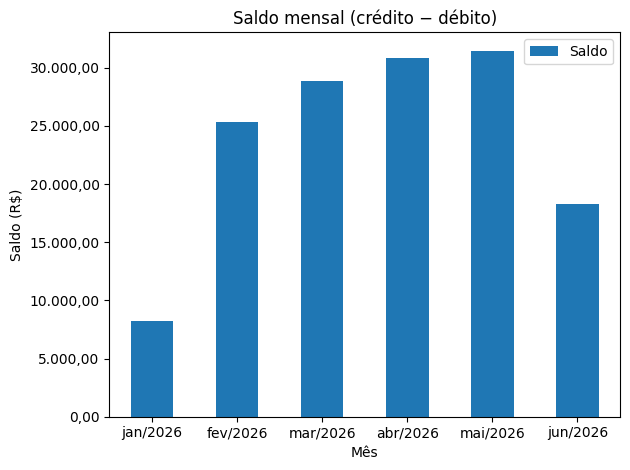

In [52]:
# ===== CÉLULA DE EXECUÇÃO PRINCIPAL =====
df = ler_transacoes_pandas(CAMINHO_ARQUIVO)

if df is None:
    print("Nenhum dado para processar.")
else:
    df_limpo = limpar_transacoes_pandas(df)
    metricas_mensais_pandas = calcular_metricas_pandas(df_limpo)
    print(metricas_mensais_pandas)
    print()
    comparar_com_nativo(df_limpo, metricas_mensais_pandas, CAMINHO_JSON_NATIVO)
    gerar_grafico_saldo(metricas_mensais_pandas)